<a href="https://www.kaggle.com/code/azharellybotnaru/is-this-a-spiral-galaxy-or-an-elliptical-galaxy?scriptVersionId=366093049" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [2]:
import urllib.request

try:
    response = urllib.request.urlopen(
        "https://www.google.com",
        timeout=10
    )
    print("Internet is working!", response.status)
except Exception as e:
    print("Connection failed:", e)

Internet is working! 200


In [3]:
import os
iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')

if iskaggle:
    %pip install -Uqq fastai ddgs

Note: you may need to restart the kernel to use updated packages.


In [4]:
from ddgs import DDGS  
from fastcore.all import *

def search_images(keywords, max_images=200): return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')
import time, json

In [5]:
import ddgs
print(ddgs.__version__)

9.16.1


In [6]:
urls = search_images('spiral galaxy photos', max_images=5)
urls[0]

'https://assets.science.nasa.gov/dynamicimage/assets/science/missions/hubble/galaxies/spiral/Hubble_NGC1961_potw2517a.jpg?w=4025&h=3799&fit=clip&crop=faces,focalpoint'

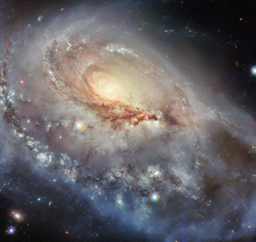

In [7]:
from fastdownload import download_url

dest = 'spiral_galaxy.jpg'
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

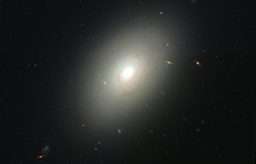

In [8]:
download_url(search_images('elliptical galaxy photos', max_images=1)[0], 'elliptical_galaxy.jpg', show_progress=False)
Image.open('elliptical_galaxy.jpg').to_thumb(256,256)

In [9]:
searches = 'spiral galaxy', 'elliptical galaxy'
path = Path('galaxy_classification')

for o in searches:
    dest = (path/o)
    dest.mkdir(exist_ok=True, parents=True)
    download_images(dest, urls=search_images(f'{o} photo'))
    time.sleep(5)
    resize_images(path/o, max_size=400, dest=path/o)

In [10]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

0

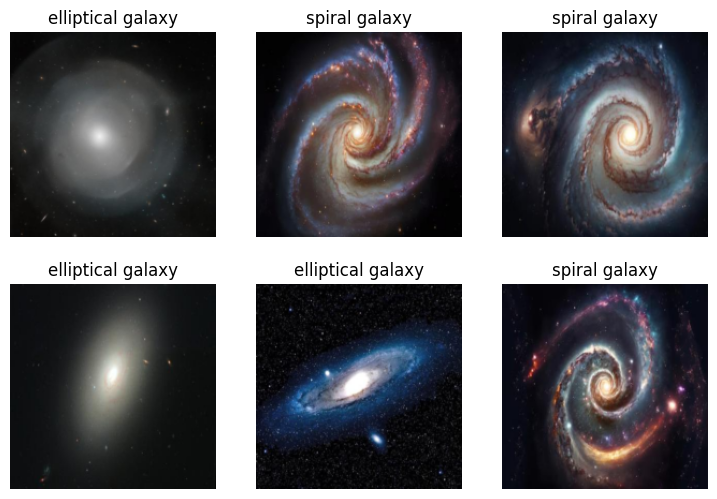

In [34]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

Image 0: 36ff12f1-0fb6-4f39-8a85-6c25db16a0b5.jpg


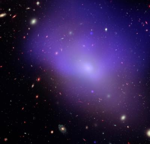

Image 1: df8e2ba0-415b-4375-88f6-95df0bcaa21a.jpg


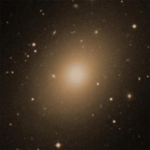

Image 2: 5d589dfc-c604-49b7-a8b9-81d422abc0b7.jpg


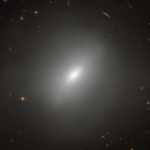

Image 3: b39dd69f-cb91-4fd3-a819-d77808b5cc58.jpg


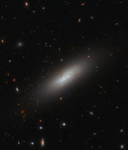

Image 4: 78aaba6a-8597-42ce-9372-cbb96c199bbc.jpg


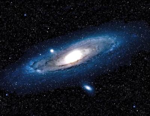

Image 5: 58f1d84e-f6a7-406e-a5c2-9ec3e6a91b5e.jpg


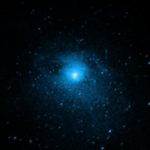

Image 6: b5edf422-b807-4ef9-85e2-b2adbef35bda.jpg


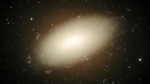

Image 7: bfd001a2-53e9-4190-80fb-c09295e1c3db.jpg


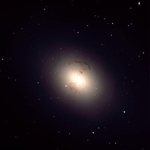

Image 8: 26b1a891-33ca-4680-bc33-3d02e07c7272.jpeg


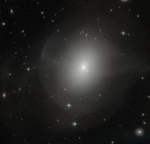

Image 9: 8fa37c95-c7f1-4df5-be9d-f793b91e18c0.jpg


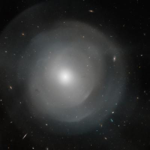

Image 10: f41d2127-1bc9-4f10-baef-3abb21baeaf9.jpg


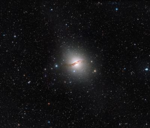

Image 11: 8cd0e474-cd93-4e60-8ba2-b9fa391f4eb1.jpg


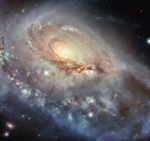

Image 12: b2cb2a13-f015-4ac7-b839-a0dff1edded0.jpg


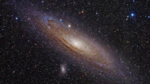

Image 13: d764f0f6-c416-49b8-8227-5ac079da0c3c.png


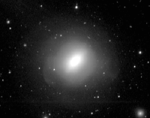

Image 14: c57e19a7-62d8-47c9-ab00-cac831bc60f3.jpg


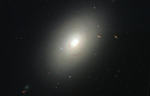

Image 15: 3fe870be-23fb-42bb-ab11-c4b2b54da833.jpg


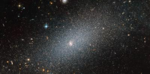

Image 16: 0d64bc45-df2a-4b18-baf0-0e0bcf18209c.jpg


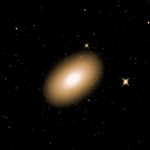

Image 17: 4527e4f0-a5d0-4145-9332-2e12fb5102be.jpg


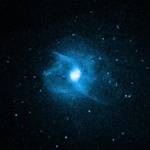

Image 18: 782b1105-19e0-4d35-8c39-de65c2dd742a.jpg


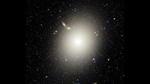

Image 19: edaee9be-86b2-4253-91f5-d71d518f9e9f.jpg


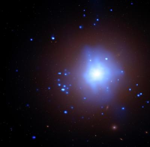

In [33]:
from IPython.display import display
from PIL import Image

folder = path / 'elliptical galaxy'
images = get_image_files(folder)

for i, file in enumerate(images[:50]):
    print(f'Image {i}: {file.name}')
    display(Image.open(file).to_thumb(150, 150))

bad_images = [0, 3, 6, 8]

for i in bad_images:
    print("Deleting:", images[i].name)
    images[i].unlink()

bad_images = [12, 16, 20, 22, 23]

for i in bad_images:
    print("Deleting:", images[i].name)
    images[i].unlink()

In [26]:
print(len(images))

20


In [27]:
print("Elliptical:", len(get_image_files(path / 'elliptical galaxy')))
print("Spiral:", len(get_image_files(path / 'spiral galaxy')))
print("Total:", len(get_image_files(path)))

Elliptical: 20
Spiral: 33
Total: 53


Image 0: 68a415a4-16e0-4202-b0f2-96bc3f96bdaf.jpg


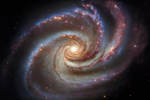

Image 1: 66138a64-cef5-45d0-8488-e58b06c5bb46.jpg


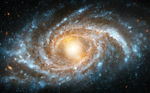

Image 2: ebc5dda7-90a0-4b61-a3bf-e730c4129904.jpg


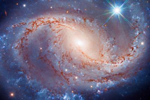

Image 3: ce0b4d14-a364-4ea9-8567-0db5c963a83c.tif


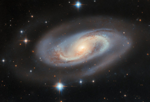

Image 4: f432bd72-42c4-48f7-aed8-64b7eca356ac.jpg


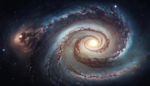

Image 5: 293beeba-b12e-431e-808b-e9cbb15e65bf.jpg


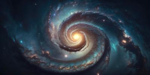

Image 6: 1ff5d26d-e11f-472a-ab75-3c00e33b77dd.jpg


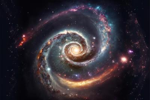

Image 7: 9ce40628-d70a-4c9f-a59b-0220f7d8a2a5.jpg


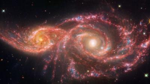

Image 8: 30d8ccb9-0d7c-434e-95ea-416bd88341c7.jpg


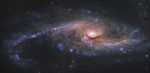

Image 9: 82fa5ae0-d181-4826-8a05-fd78e469754a.jpg


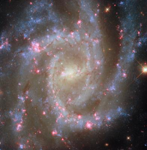

Image 10: 6824f835-10c0-4ec3-afe5-91a5e8059011.jpg


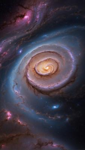

Image 11: b808b6d6-002c-4ffb-b3d4-46decee9187c.jpg


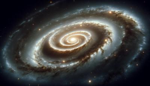

Image 12: 9c6e1abe-3434-4c31-9a87-3424cad060ec.jpg


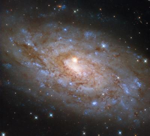

Image 13: 3ca62bc8-3042-44b6-9435-a9b42daca081.jpg


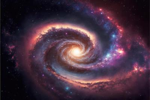

Image 14: 20e32de3-8f6d-4bc6-b389-57ec205679f2.jpg


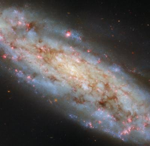

Image 15: c6641a4e-10df-4e0c-850c-e30f4aaff0e0.jpg


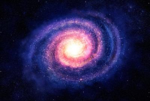

Image 16: 8081a394-e9a1-4b6a-979f-0d6c2d7512e6.jpg


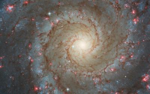

Image 17: 440789f5-07fb-4475-857d-3e11293d177f.jpg


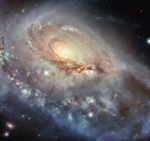

Image 18: a35c26bc-abd8-4006-8ef2-9af3fcfd6e65.jpg


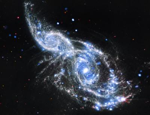

Image 19: c2e1eb40-49bc-4870-ba43-ac5341efd08c.jpg


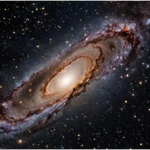

Image 20: 7f79928b-d992-475f-88ba-421d6aff6f7b.jpg


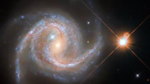

Image 21: 05309d0d-eacf-48a2-a0cb-b447b8b6448d.jpg


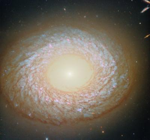

Image 22: 87d1b081-7d5c-4509-9f44-6f3e474d4f22.jpg


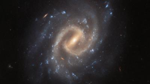

Image 23: 6776b359-1d23-46e4-943c-3cb20adfe634.jpg


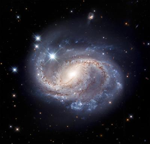

In [32]:
from IPython.display import display
from PIL import Image

folder = path / 'spiral galaxy'
images = get_image_files(folder)

for i, file in enumerate(images[:50]):
    print(f'Image {i}: {file.name}')
    display(Image.open(file).to_thumb(150, 150))

bad_images = []

for i in bad_images:
    print("Deleting:", images[i].name)
    images[i].unlink()

In [35]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 145MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.341915,3.211557,0.375000,00:03


epoch,train_loss,valid_loss,error_rate,time
0,1.023804,2.382120,0.375000,00:04
1,0.905947,1.174616,0.375000,00:04
2,0.615160,1.048230,0.375000,00:05


In [36]:
galaxy_type, _, probs = learn.predict(PILImage.create('spiral_galaxy.jpg'))

print(f"This is a: {galaxy_type}.")
print(f"Probability it's a {galaxy_type}: {probs.max():.4f}")

This is a: spiral galaxy.
Probability it's a spiral galaxy: 0.9880


In [37]:
galaxy_type, _, probs = learn.predict(PILImage.create('elliptical_galaxy.jpg'))

print(f"This is a: {galaxy_type}.")
print(f"Probability it's a {galaxy_type}: {probs.max():.4f}")

This is a: elliptical galaxy.
Probability it's a elliptical galaxy: 0.9998
